# Preamble

In [9]:
# General Imports
import sys
import os
import numpy as np
import datetime as dt

# Data processesing imports
import pandas as pd
import sqlite3

# Visualization imports
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [10]:
# Initialize SQLite Connection and Cursor objects
conn = sqlite3.connect('data/revolut_home_task.db')
cursor = conn.cursor()

# Query and export analysis datasets

## User Centric Queries

In [11]:
# Query Gross profit per user by country, user_type, plan, state, onboarding month and napped status
# Include decile tags for gross profit in totality and by user type
# Include tag for identify users impacted by the Vending Machine campaing
cursor.execute('DROP TABLE IF EXISTS gp_per_user')

with open('sql-queries/gp_per_user.sql','r') as f:
    query = f.read()
    f.close()
cursor.execute(query)

In [12]:
# Query summary that aggregates for each segment
with open('sql-queries/gp_per_user_summary.sql','r') as f:
    query = f.read()
    f.close()
gp_per_user = pd.read_sql(query, conn)
gp_per_user.to_csv('outputs/gp_per_user.csv',index=False)

## Account level Query

In [14]:
# Query gross profit by account combination, user details, and by user gp decile tags
with open('sql-queries/account-level-summary.sql','r') as f:
    query = f.read()
    f.close()
account_summary = pd.read_sql(query,conn)
account_summary.to_csv('outputs/account_summary.csv',index=False)

In [3]:
# Query number of distinct users, by city and country.
with open('sql-queries/user-city-country.sql','r') as f:
    query = f.read()
    f.close()

user_ref_data = pd.read_sql(query,conn)

In [4]:
## First we want to double check that each user corresponds to a unique city/country combination
user_entry_count = user_ref_data\
    .reset_index()\
    .groupby('user_id')\
    .agg(unique_entry_count = ('index','count'))

if (user_entry_count.unique_entry_count > 1).any():
    print('Instances of multiple cities/countries per user found')
else:
    print('Each user has one city/country')

Instances of multiple cities/countries per user found


In [5]:
## Create a table containing latest city/country combination per user
cursor.execute("DROP TABLE IF EXISTS latest_user_address")
with open('sql-queries/latest-user-address.sql','r') as f:
    query = f.read()
    f.close()
cursor.execute(query)
print("Latest user addresses queried and loaded to latest_user_address")

Latest user addresses queried and loaded to latest_user_address


In [6]:
## Query the User address table
user_addresses = pd.read_sql("SELECT * FROM latest_user_address",conn)

## Group by city and country, and aggregate
user_address_summary = user_addresses\
    .groupby(['user_country','user_city'])\
    .agg(users=('user_id','count'))\
    .sort_values(by='users',ascending=False)

user_address_summary.head()

,,users
user_country,user_city,
United Kingdom,London,7344
Ireland,Dublin,3671
Hungary,Budapest,2518
France,Paris,2141
Poland,Warszawa,1686


In [7]:
## Export to CSV
user_address_summary.to_csv('outputs/user_locations.csv')

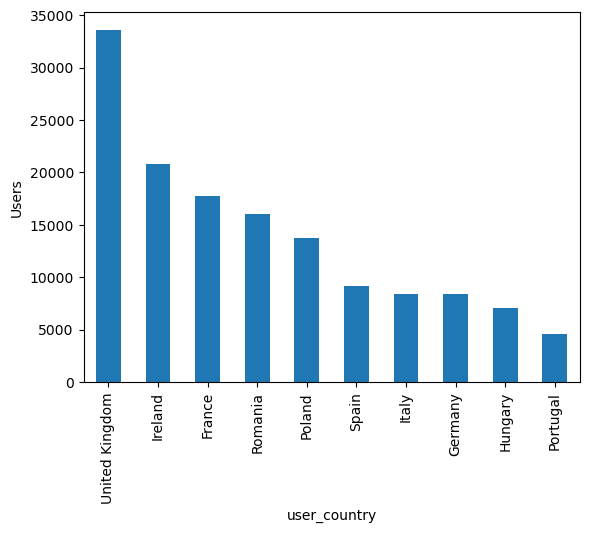

In [8]:
## Plot bar chart of user counts in top 10 countries
users_by_country_plot = user_address_summary\
    .reset_index()\
    .groupby('user_country')\
    .agg(users = ('users','sum'))\
    .sort_values(by='users',ascending=False)\
    .head(10)\
    .plot(y='users',kind='bar',legend=False,ylabel='Users')
users_by_country_plot.get_figure().savefig('figures/users_per_country.png')

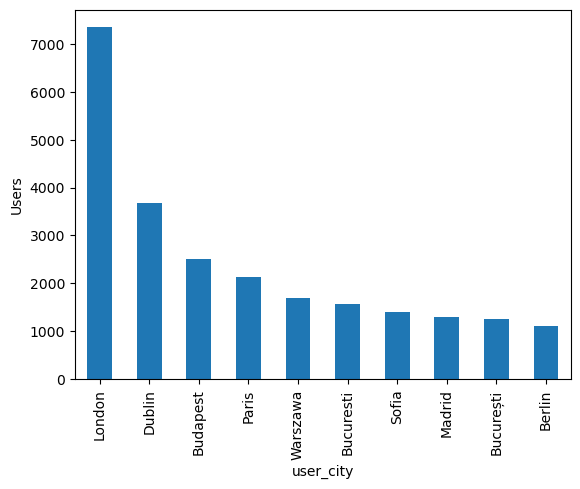

In [9]:
## Plot bar chart of user counts by city for top 10 cities
users_by_city_plot = user_address_summary\
    .reset_index()\
    .groupby('user_city')\
    .agg(users = ('users','sum'))\
    .sort_values(by='users',ascending=False)\
    .head(10)\
    .plot(kind='bar',legend=False,ylabel='Users')
users_by_city_plot.get_figure().savefig('figures/users_by_city_plot.png')

In [10]:
# Print count of distinct users, countries, cities
no_users = user_address_summary.users.sum()
no_cities = np.unique(
    user_address_summary\
        .reset_index()\
        .user_city\
        .to_numpy()
).shape[0]
no_countries = np.unique(
    user_address_summary\
        .reset_index()\
        .user_country\
        .to_numpy()
).shape[0]

print('Distinct users: ', no_users)
print('Distinct user countries: ', no_countries)
print('Distinct user cities: ', no_cities)

Distinct users:  183532
Distinct user countries:  62
Distinct user cities:  35957


## Users by age group

In [11]:
# Query latest user age, by user type and country

with open('sql-queries/latest-user-age-country.sql','r') as f:
    query = f.read()
    f.close()
user_age_summary = pd.read_sql(query, conn)
user_age_summary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 524 entries, 0 to 523
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   age_group     442 non-null    object
 1   user_country  524 non-null    object
 2   user_type     524 non-null    object
 3   users         524 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 16.5+ KB


In [12]:
# Check which user type has the most null age grouups
user_age_summary[user_age_summary.age_group.isnull()].groupby('user_type').agg(users=('users','sum')).head(10)

,users
user_type,
BUSINESS,2328
BUSINESS_USER,2
COMPANY,9
PERSONAL,1328
YOUTH,2


## Date span

In [13]:
# Retrieve P&L entries by pnl date
with open('sql-queries/entries-by-pnl-month.sql','r') as f:
    query = f.read()
    f.close()

entry_timeline = pd.read_sql(query,conn)

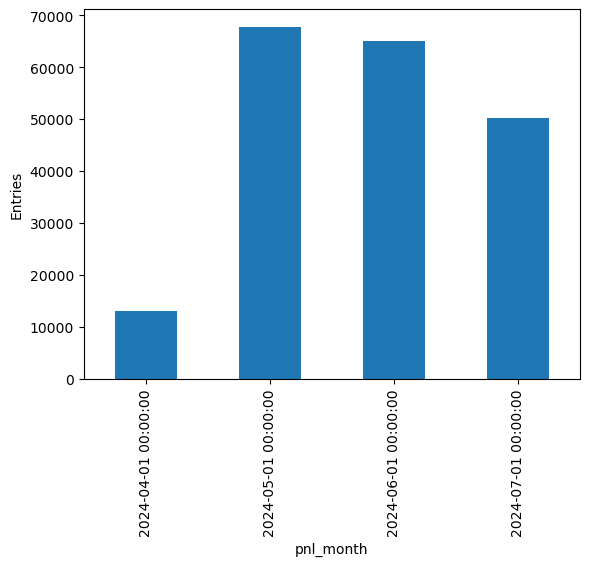

In [14]:
# Plot bar chart showing entries
entry_timeline_plot = entry_timeline.plot(
    x='pnl_month',
    y='entries',
    kind='bar',
    legend=False,
    ylabel='Entries'
)
entry_timeline_plot.get_figure().savefig('figures/entry_timeline.png')

In [15]:
# Query first and last pnl date
with open('sql-queries/min-max-dates.sql','r') as f:
    query = f.read()
    f.close()
min_max_dates = pd.read_sql(query,conn)
min_date = dt.datetime.strptime(min_max_dates.loc[0,'first_date'], '%Y-%m-%d %H:%M:%S')
max_date = dt.datetime.strptime(min_max_dates.loc[0,'last_date'], '%Y-%m-%d %H:%M:%S')
duration_days = (max_date - min_date).days
print('First Pnl date: ',min_date)
print('Last Pnl date: ', max_date)
print('Duration: ',duration_days)

First Pnl date:  2024-04-24 00:00:00
Last Pnl date:  2024-07-23 00:00:00
Duration:  90


# GP Breakdown

In [12]:
# Query GP by accounts 1 - 4, user country, user type, user plan
with open('sql-queries/gp-by-segment.sql','r') as f:
    query = f.read()
    f.close()
gp_by_segment = pd.read_sql(query,conn)
gp_by_segment.to_csv('outputs/gp-by-segment.csv',index=False)

## Top Down Account analysis

See [excel](https://1drv.ms/x/c/35e16cc9757236a7/IQAmG5Avl_KbS5XbFipZKbLQAddwKY8QcLWWc-3du_rsbHI?e=SmTSzT)

## By User Type

## By plan (product)

## By country
- With breakdown by age

# Initiative analysis

## Loan interest rate reduction in Lithuania, Romania and Germany

__Hypothesis__: A reduction in loan interest rates should decrease the average profitability of loans in these markets, while simaltaneously making them more attractive to customers. We would therefore expect to see:
- Reduced loan interest income / distinct loan user
- Increase in loan user rate (loan users/ total active users in the market at the time)

To verify this, need to check compare the above KPIs:
- last 30 days vs first 30 days
- vs benchmark markets, by age group

In [10]:
# Query interest and provision amounts by country, plan and pnl month
with open('sql-queries/loan_impact.sql','r') as f:
    query = f.read()
    f.close()
loan_impact_df = pd.read_sql(
    query,
    conn,
    parse_dates=['pnl_month']
    )
loan_impact_df.to_csv('outputs/loan_impact.csv',index=False)

In [ ]:
# Pre vs post analysis: show loan intrest revenue/loan user for the three periods by market


In [4]:
# Benchmark analysis vs other markets

In [6]:
# Query loan usage rates
with open('sql-queries/loan_impact_usage.sql','r') as f:
    query = f.read()
    f.close()
loan_usage_df = pd.read_sql(
    query,
    conn
)
loan_usage_df.to_csv('outputs/loan_usage.csv',index=False)

In [ ]:
# Compare loan usage rates across markets

Findings are inconclusive:
- Interest per user is declining for the 3 markets, but the same is true for others (France)
- Average loan/user efficiency is not significantly lower than other markets
- Loan usage rate in Romania and Lithuania is higher, which may indicate a higher pickup in these countries, but Germany is in the middle of the pack

More information needed for conclusive evaluation of the impact:
- How material were the interest rate reductions (in terms of % APR)
- When did the change come into affect
- What is the principle and outstanding loan values (accounts receivable) associated with the loans?

## Instant Access savings account rate increase
Similarly to the above, I hypothesize that the impact will be:
- Increase in interest rates paid to the users, adverse impact on GP/user
- Higher rate should attract more customers to the product, more users 

In [11]:
# Query savings GP and users, by country, plan 

 Findings show that the GP/user earned from Ultra and metal are significantly higher than others

## Growth vending machine campaign

# Postamble

In [6]:
tables = pd.read_sql(
    "SELECT name, type FROM sqlite_master WHERE type IN ('table','view')",
    conn
)
print(tables)

                  name   type
0  latest_user_address  table
1      user_monthly_gp  table
2          gp_per_user  table


In [15]:
cursor.close()
conn.close()